# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio en un archivo de
texto estructurado y buscable?

| Registro | Valor |
|---|---|
| Fecha de extracción | 25 de octubre de 2026 (la celda 1 imprime la fecha real de ejecución) |
| Entorno | `entorno/` = `pyproject.toml` + `uv.lock` del curso: `uv sync --group docai --group audio --group llm` |
| OCR | **PaddleOCR 3.7.0**, modelo PP-OCRv6 (multilingüe, incluye español), motor PyTorch, CPU |
| ASR | **faster-whisper 1.2.1**, modelo **small** (`Systran/faster-whisper-small`, int8, CPU), VAD Silero, `language="es"` |
| Diarización | huellas de voz WeSpeaker ResNet34 (`pyannote/wespeaker-voxceleb-resnet34-LM`) + clustering jerárquico (`voz.diarizar`, Sesión 13) |

### Fuentes y licencias

| Corpus | Fuente | Licencia | Cómo se obtiene |
|---|---|---|---|
| Documentos impresos, fotos y manuscritos peruanos | [Wikimedia Commons](https://commons.wikimedia.org) (los 16 documentos verificados en la clase de PaddleOCR de la Sesión 10 + búsquedas en la API) | Dominio público, CC0, CC BY 3.0/4.0, CC BY-SA 3.0/4.0 (cada archivo en `datos/fuentes.csv`) | `src/descargar.py` → API de Commons, solo licencias libres y categorías peruanas |
| Capturas propias (opcional) | Fotos del estudiante sin datos personales | CC BY 4.0 | `datos/propios/propios.csv` |
| Entrevistas reales | Wikimedia Commons (El Agustino, Lima; dirigente de organización de mujeres indígenas; otras halladas por la API) | CC BY-SA 4.0 u otra libre (ver `datos/fuentes.csv`) | `src/descargar.py` |
| Español peruano leído | [OpenSLR 73](https://www.openslr.org/73/) — Guevara-Rukoz et al. (2020), *Crowdsourcing Latin American Spanish for Low-Resource Text-to-Speech*, LREC | CC BY-SA 4.0 | lectura parcial del zip por HTTP Range (como `datos.py`, Sesión 13) |

La atribución completa de **cada** archivo (título, autor, licencia, URL y forma de recuperarlo) se
exporta al final a `datos/fuentes.csv`. Los archivos originales quedan en `datos/raw/` (fuera de Git).

In [1]:
import os, sys, json, re, time, warnings
from pathlib import Path

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # Windows: PyTorch y Paddle traen cada uno su OpenMP
warnings.filterwarnings("ignore")

RAIZ = Path.cwd()
assert (RAIZ / "src" / "t2.py").exists(), "Abre este notebook desde la carpeta tarea_2/"
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import soundfile as sf
from PIL import Image
from importlib.metadata import version

import descargar, t2, voz

RAW = RAIZ / "datos" / "raw"
SR = voz.SR
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

print("Fecha de ejecución:", time.strftime("%Y-%m-%d %H:%M"))
for p in ["paddleocr", "paddlepaddle", "faster-whisper", "ctranslate2", "torch", "transformers",
          "pyannote.audio", "pandas", "plotly"]:
    try:
        print(f"  {p:<15} {version(p)}")
    except Exception:
        print(f"  {p:<15} (no instalado)")

Fecha de ejecución: 2026-10-25 20:42
  paddleocr       3.7.0
  paddlepaddle    3.3.1
  faster-whisper  1.2.1
  ctranslate2     4.8.2
  torch           2.13.0
  transformers    5.16.1
  pyannote.audio  4.0.7
  pandas          2.3.3
  plotly          7.0.0


## 1 · Recolección de los corpus

`descargar.documentos()` baja primero los documentos peruanos verificados en la Sesión 10, luego
las capturas propias (si las hay) y completa las cuotas **8 impresos / 8 fotos / 9 manuscritos** con
búsquedas en la API de Commons, **más 3 de reserva por tipo** para reemplazar descartes. Solo acepta
licencias libres (sin NC/ND) y archivos con categorías peruanas. Usa un User-Agent descriptivo y
pausas de 1,2 s entre solicitudes. Si ya existe `datos/raw/documentos/inventario.csv`, no vuelve a bajar nada.

In [2]:
inv_docs = descargar.documentos()
inv_docs[["id", "tipo", "titulo", "licencia", "origen"]]


Documentos por tipo: {'manuscrito': 12, 'foto': 11, 'impreso': 9}


,id,tipo,titulo,licencia,origen
0,doc_001,impreso,Acta de Creación de los Símbolos para el Distrito de Mache.jpg,CC BY 4.0,Wikimedia Commons (verificado en Sesión 10)
1,doc_002,impreso,Pisco-punch-mercurio-peruano-1791.jpg,Public domain,Wikimedia Commons (verificado en Sesión 10)
2,doc_003,impreso,10 Intis 1987(front).jpg,CC0,Wikimedia Commons (verificado en Sesión 10)
3,doc_004,impreso,100 Intis 1987(Front).jpg,CC0,Wikimedia Commons (verificado en Sesión 10)
4,doc_005,impreso,1000 Intis 1988(Front).jpg,CC0,Wikimedia Commons (verificado en Sesión 10)
5,doc_006,impreso,10000 Intis 1988(Front).jpg,CC0,Wikimedia Commons (verificado en Sesión 10)
6,doc_007,impreso,500000 Intis 1988(Front).jpg,CC0,Wikimedia Commons (verificado en Sesión 10)
7,doc_008,impreso,5000000 Intis 1990(Front).jpg,CC0,Wikimedia Commons (verificado en Sesión 10)
8,doc_009,impreso,50 Intis 1987(Front).jpg,CC0,Wikimedia Commons (verificado en Sesión 10)
9,doc_010,foto,Placa Calle Capon.jpg,CC BY 3.0,Wikimedia Commons (verificado en Sesión 10)


`descargar.audios()` baja las entrevistas de Commons (las de la Sesión 13 y otras en español peruano
que encuentre la API, como máximo ~18 min) y completa hasta ~36 min con **sesiones de lectura** de
OpenSLR 73: diez frases de un mismo hablante unidas con 0,6 s de pausa (un clip de ~50 s por
hablante), cada una con su transcripción humana oficial. También arma la **entrevista simulada** de
dos hablantes reales (14 turnos), de la que se conoce quién habla cuándo.

In [3]:
inv_audio = descargar.audios(minutos_objetivo=36)
inv_audio[["id_fuente", "idioma", "origen", "duracion_seg", "licencia"]]

Inventario de audio ya existe (21 fuentes). Bórralo para volver a bajar.


,id_fuente,idioma,origen,duracion_seg,licencia
0,commons_01,es,Wikimedia Commons (verificado en Sesión 13),136.3,CC BY-SA 4.0
1,commons_02,es,Wikimedia Commons (verificado en Sesión 13),189.0,CC BY-SA 4.0
2,commons_03,es,Wikimedia Commons (verificado en Sesión 13),250.6,CC BY-SA 4.0
3,commons_04,qwh,Wikimedia Commons (verificado en Sesión 13),94.1,CC BY-SA 4.0
4,commons_05,es,Wikimedia Commons (búsqueda API),77.4,CC BY-SA 4.0
5,commons_06,es,Wikimedia Commons (búsqueda API),98.3,CC BY-SA 4.0
6,commons_07,es,Wikimedia Commons (búsqueda API),81.6,CC BY-SA 4.0
7,commons_08,es,Wikimedia Commons (búsqueda API),54.3,CC BY-SA 4.0
8,commons_09,es,Wikimedia Commons (búsqueda API),497.7,CC BY-SA 4.0
9,openslr73_pef_01523,es,OpenSLR 73,70.6,CC BY-SA 4.0


## 2 · Limpieza de documentos: duplicados, archivos dañados y revisión visual

1. **Duplicados por hash**: dos archivos con el mismo SHA-256 son el mismo documento.
2. **Archivos que no abren** se descartan.
3. **Revisión humana**: la grilla de abajo muestra todos los candidatos. Si alguno no es peruano, no
   es del tipo indicado (por ejemplo, una «foto» sin sombra ni inclinación) o tiene datos personales,
   se anota en `datos/descartes_manual.csv` (`id,motivo`) y se vuelve a ejecutar el notebook: se usa
   uno de reserva.

In [4]:
descartes = []   # (id, modalidad, motivo) — se reportan al final

docs = inv_docs.copy()
for r in docs[docs.duplicated("sha256", keep="first")].itertuples():
    descartes.append((r.id, "documento", "duplicado (mismo SHA-256 que otro archivo)"))

def abre(ruta):
    try:
        with Image.open(RAIZ / ruta) as im:
            im.verify()
        return True
    except Exception:
        return False

for r in docs[~docs["archivo"].map(abre)].itertuples():
    descartes.append((r.id, "documento", "archivo de imagen dañado o ilegible por PIL"))

ruta_dm = RAIZ / "datos" / "descartes_manual.csv"
if not ruta_dm.exists():
    pd.DataFrame(columns=["id", "motivo"]).to_csv(ruta_dm, index=False)
manual = pd.read_csv(ruta_dm, dtype=str, keep_default_na=False)
for r in manual.itertuples():
    descartes.append((r.id, "documento", f"revisión manual: {r.motivo}"))

ids_fuera = {d[0] for d in descartes}
candidatos = docs[~docs["id"].isin(ids_fuera)].reset_index(drop=True)
print(f"{len(docs)} documentos bajados · {len(ids_fuera)} descartados antes del OCR · {len(candidatos)} candidatos")
print(candidatos["tipo"].value_counts().to_string())

32 documentos bajados · 3 descartados antes del OCR · 29 candidatos
tipo
foto          10
manuscrito    10
impreso        9


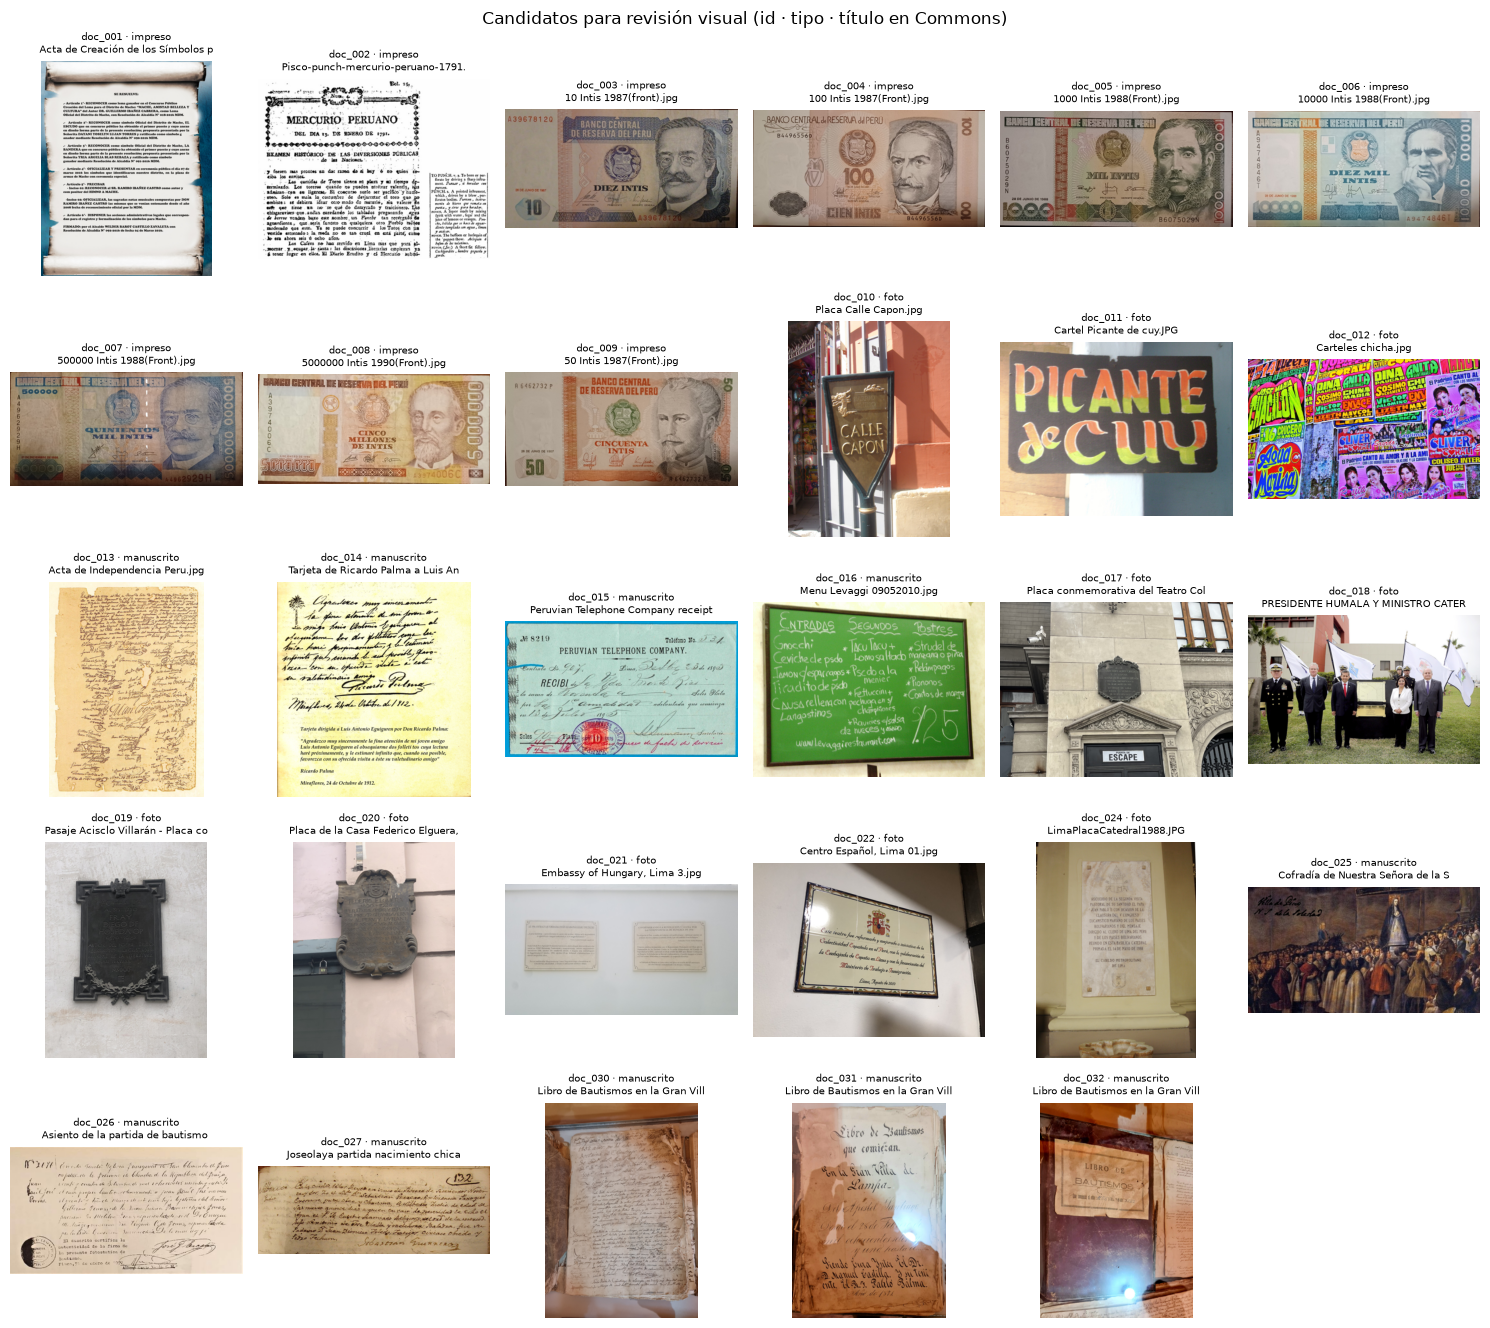

In [5]:
n = len(candidatos)
cols = 6
fig, ejes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(15, 2.7 * np.ceil(n / cols)))
for eje in ejes.flat:
    eje.axis("off")
for eje, r in zip(ejes.flat, candidatos.itertuples()):
    im = Image.open(RAIZ / r.archivo).convert("RGB")
    im.thumbnail((400, 400))
    eje.imshow(im)
    eje.set_title(f"{r.id} · {r.tipo}\n{r.titulo[:34]}", fontsize=7.5)
fig.suptitle("Candidatos para revisión visual (id · tipo · título en Commons)", fontsize=12)
fig.tight_layout()
plt.show()
plt.close("all")

## 3 · OCR con PaddleOCR (línea base del corpus)

Parámetros (iguales para los tres tipos de documento):

- **Modelo:** PP-OCRv6 por defecto de PaddleOCR 3.7 (detector + reconocedor multilingüe con español).
- **Motor:** PyTorch (`engine="transformers"`), CPU. Si falla, el motor PaddlePaddle.
- `use_doc_orientation_classify=False`, `use_doc_unwarping=False`, `use_textline_orientation=False`.
- **Preprocesamiento:** solo corrección de rotación EXIF, conversión a RGB y lado mayor ≤ 2000 px
  (`t2.preparar_imagen`). No se binariza ni se mejora el contraste.

Respaldo crudo: las líneas con su caja y confianza se guardan en `datos/raw/documentos/ocr_json/`,
y los recortes de las 8 líneas de menor confianza de cada documento (para revisión humana) en
`datos/raw/documentos/recortes/`. Los resultados se guardan en caché: volver a ejecutar no repite el OCR.

In [6]:
ocr_base, MODELO_OCR = t2.crear_paddle(t2.OPCIONES_BASE, device="cpu")
print(MODELO_OCR)

DIR_PROC, DIR_JSON, DIR_REC = (RAW / "documentos" / c for c in ("procesadas", "ocr_json", "recortes"))
for d in (DIR_PROC, DIR_JSON, DIR_REC):
    d.mkdir(parents=True, exist_ok=True)

lecturas, filas_ocr = {}, []
t_inicio = time.perf_counter()
for r in candidatos.itertuples():
    proc = t2.preparar_imagen(RAIZ / r.archivo, DIR_PROC)
    cache = DIR_JSON / f"{r.id}.json"
    if cache.exists():
        guardado = json.loads(cache.read_text(encoding="utf-8"))
        lineas = pd.DataFrame(guardado["lineas"]) if guardado["lineas"] else t2.lineas_vacias()
        seg = guardado["segundos"]
    else:
        t0 = time.perf_counter()
        lineas = t2.leer_paddle(ocr_base, proc)
        seg = time.perf_counter() - t0
        cache.write_text(json.dumps({"id": r.id, "modelo": MODELO_OCR, "segundos": seg,
                                     "lineas": lineas.to_dict("records")}, ensure_ascii=False, indent=1,
                                    default=float), encoding="utf-8")
        im = Image.open(proc)
        (DIR_REC / r.id).mkdir(exist_ok=True)
        for k, l in enumerate(lineas.nsmallest(8, "confianza").itertuples()):
            if l.x1 > l.x0 and l.y1 > l.y0:
                im.crop((int(l.x0), int(l.y0), int(l.x1), int(l.y1))).save(DIR_REC / r.id / f"linea_{k:02d}_conf{l.confianza:.2f}.png")
    lecturas[r.id] = lineas
    texto = t2.texto_de_lineas(lineas)
    filas_ocr.append({"id": r.id, "texto_ocr_crudo": texto, "n_lineas": len(lineas), "n_caracteres": len(texto),
                      "confianza_mediana": float(lineas["confianza"].median()) if len(lineas) else np.nan,
                      "pct_lineas_dudosas": float((lineas["confianza"] < 0.9).mean() * 100) if len(lineas) else np.nan,
                      "segundos_ocr": round(seg, 2), "imagen_procesada": proc.relative_to(RAIZ).as_posix()})
    print(f"{r.id} [{r.tipo:<10}] {len(lineas):3d} líneas · conf. mediana {filas_ocr[-1]['confianza_mediana']:.2f} · {seg:5.1f} s")

ocr = candidatos.merge(pd.DataFrame(filas_ocr), on="id")
print(f"\nOCR de {len(ocr)} documentos en {time.perf_counter() - t_inicio:.0f} s")

# liberar memoria: el modelo de OCR ya no se usa en este notebook (evita que el kernel se caiga en el ASR)
import gc
del ocr_base
gc.collect()

Creating model: ('PP-OCRv6_medium_det', None, 'transformers')


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\PC\.paddlex\official_models\PP-OCRv6_medium_det_safetensors`.


Creating model: ('PP-OCRv6_medium_rec', None, 'transformers')


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\PC\.paddlex\official_models\PP-OCRv6_medium_rec_safetensors`.


PaddleOCR 3.7.0 PP-OCRv6 · motor transformers (PyTorch) · cpu · sin preprocesamiento extra
doc_001 [impreso   ]  28 líneas · conf. mediana 0.99 · 148.7 s
doc_002 [impreso   ]  44 líneas · conf. mediana 0.97 · 123.0 s
doc_003 [impreso   ]  12 líneas · conf. mediana 0.98 ·  25.9 s
doc_004 [impreso   ]  15 líneas · conf. mediana 1.00 ·  29.4 s
doc_005 [impreso   ]  10 líneas · conf. mediana 1.00 ·  25.8 s
doc_006 [impreso   ]  11 líneas · conf. mediana 1.00 ·  28.5 s
doc_007 [impreso   ]  14 líneas · conf. mediana 1.00 ·  32.0 s
doc_008 [impreso   ]  13 líneas · conf. mediana 1.00 ·  29.0 s
doc_009 [impreso   ]  14 líneas · conf. mediana 0.99 ·  28.1 s
doc_010 [foto      ]   7 líneas · conf. mediana 1.00 ·  26.9 s
doc_011 [foto      ]   0 líneas · conf. mediana nan ·  17.9 s
doc_012 [foto      ]  97 líneas · conf. mediana 0.99 · 112.6 s
doc_013 [manuscrito]  46 líneas · conf. mediana 0.60 ·  60.8 s
doc_014 [manuscrito]  13 líneas · conf. mediana 0.77 ·  48.1 s
doc_015 [manuscrito]  17 lín

11165

### 3.1 · Lo que ve el modelo en cada tipo de documento

Cajas de cada línea detectada, coloreadas por confianza (verde ≥ 0,90; ámbar 0,70–0,90; rojo < 0,70),
en el primer documento de cada tipo.

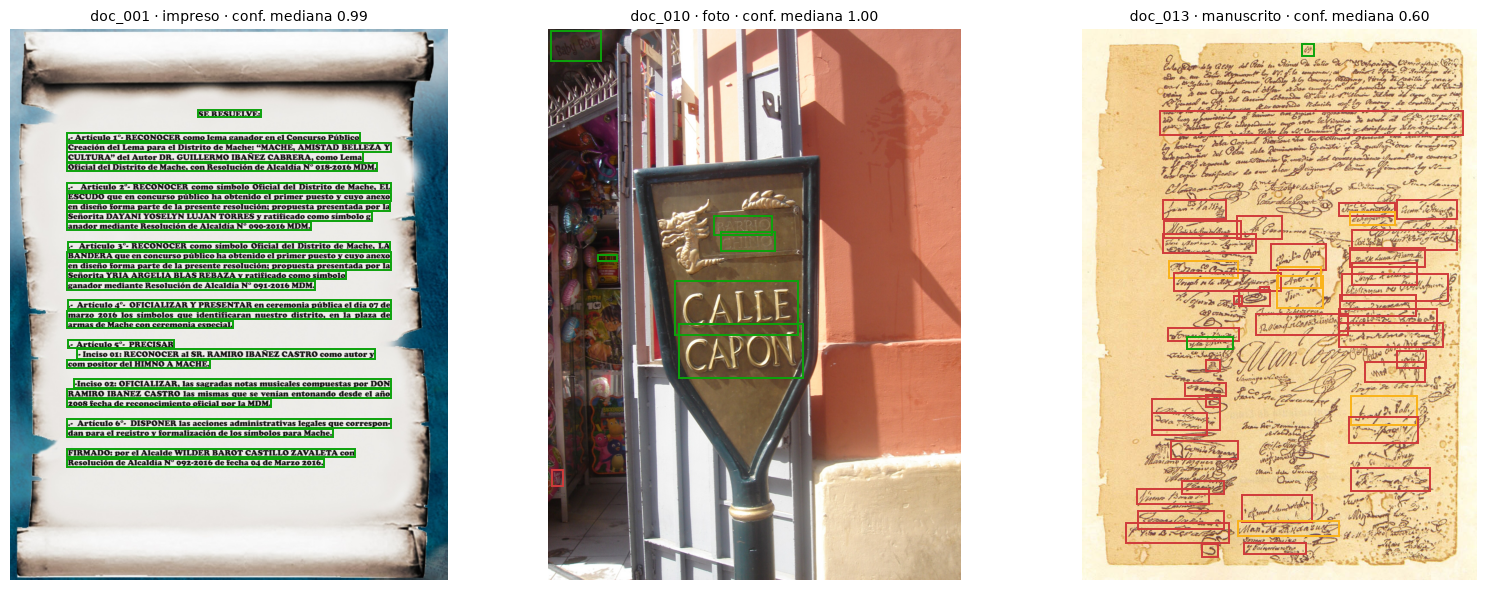

In [7]:
from matplotlib.patches import Rectangle

def color(c):
    return "#0ca30c" if c >= 0.9 else "#fab219" if c >= 0.7 else "#d03b3b"

fig, ejes = plt.subplots(1, 3, figsize=(16, 6))
for eje, tipo in zip(ejes, ["impreso", "foto", "manuscrito"]):
    r = ocr[ocr["tipo"] == tipo].iloc[0]
    eje.imshow(Image.open(RAIZ / r.imagen_procesada))
    for l in lecturas[r.id].itertuples():
        eje.add_patch(Rectangle((l.x0, l.y0), l.x1 - l.x0, l.y1 - l.y0, fill=False, lw=1.4, edgecolor=color(l.confianza)))
    eje.set_title(f"{r.id} · {tipo} · conf. mediana {r.confianza_mediana:.2f}", fontsize=10)
    eje.axis("off")
plt.tight_layout()
plt.show()
plt.close("all")

### 3.2 · Documentos ilegibles y selección final del corpus

Regla fijada de antemano: un documento es **ilegible** si el OCR no detecta ninguna línea o devuelve
menos de 15 caracteres. Un manuscrito con texto mal leído **no** se descarta: es justamente un caso
difícil que se analiza en la Parte 2.

Luego se toman, en orden de id, los primeros **8 impresos, 8 fotos y 9 manuscritos** válidos. Los
demás quedan como reserva (no se usan ni se publican).

In [8]:
CUOTAS = descargar.CUOTAS
ilegibles = ocr[(ocr["n_lineas"] == 0) | (ocr["n_caracteres"] < 15)]
for r in ilegibles.itertuples():
    descartes.append((r.id, "documento", f"ilegible: el OCR devolvió {r.n_caracteres} caracteres"))

validos = ocr[~ocr["id"].isin(ilegibles["id"])]
corpus_docs = pd.concat([validos[validos["tipo"] == t].head(n) for t, n in CUOTAS.items()]).sort_values("id").reset_index(drop=True)
reserva = validos[~validos["id"].isin(corpus_docs["id"])]

print("Corpus de documentos:", corpus_docs["tipo"].value_counts().reindex(list(CUOTAS)).to_dict(), "· total", len(corpus_docs))
print("En reserva (no usados):", list(reserva["id"]))
faltan = {t: n - (corpus_docs["tipo"] == t).sum() for t, n in CUOTAS.items() if (corpus_docs["tipo"] == t).sum() < n}
if faltan:
    print("⚠️ FALTAN documentos:", faltan, "→ agrega capturas propias en datos/propios/ o más búsquedas y vuelve a ejecutar.")

Corpus de documentos: {'impreso': 8, 'foto': 8, 'manuscrito': 9} · total 25
En reserva (no usados): ['doc_009', 'doc_032']


## 4 · ASR: VAD, transcripción con faster-whisper y diarización

Para cada archivo de audio:

1. `voz.cargar_audio` lo convierte a mono 16 kHz.
2. **VAD (Silero)**: si tiene menos de 3 s de voz, se descarta como «audio sin voz».
3. Las entrevistas de Commons de más de 100 s se **cortan en clips de ~75 s**, siempre en un silencio
   detectado por el VAD (`t2.cortar_en_clips`). Las sesiones de OpenSLR 73 (~50 s) quedan enteras.
4. **Transcripción** con faster-whisper small en CPU (`beam_size=5`, `vad_filter=True`, `language="es"`).
   El VAD evita que Whisper «alucine» frases en silencios o música.
5. **Diarización** (`voz.diarizar`, umbral coseno 0,7, sin fijar el número de hablantes) en todos los
   clips que pueden tener varias voces: las entrevistas de Commons y la entrevista simulada. Las
   sesiones de OpenSLR 73 tienen **un solo lector por construcción** (`n_hablantes = 1`, sin diarizar).
6. **Exportación** de cada clip a CSV (segmentos), SRT (subtítulos) y TXT (turnos), en
   `datos/raw/audio/salidas/` (fuera de Git, porque aún no están seudonimizados).

El audio en quechua de Huaylas se reserva para la bonificación con MMS (Parte 2) y no entra a este corpus.

In [9]:
asr = voz.Transcriptor("faster-whisper-small")
MODELO_ASR = "faster-whisper small (Systran/faster-whisper-small, int8, CPU) · beam 5 · VAD Silero on · language=es"
print(asr, f"· cargado en {asr.segundos_carga:.1f} s")

DIR_CLIPS, DIR_SAL = RAW / "audio" / "clips", RAW / "audio" / "salidas"
DIR_CLIPS.mkdir(parents=True, exist_ok=True)
DIR_SAL.mkdir(parents=True, exist_ok=True)

def condicion(f):
    if f.id_fuente == "entrevista_simulada":
        return "multihablante (simulada)"
    return "lectura (OpenSLR 73)" if f.origen == "OpenSLR 73" else "entrevista real (Commons)"

def con_marcas(segs):
    # [HABLANTE_1] texto ... con un turno por cambio de hablante
    turnos = []
    for s in segs:
        h = f"HABLANTE_{s.hablante[1:]}" if s.hablante else None
        if turnos and turnos[-1][0] == h:
            turnos[-1][1].append(s.texto)
        else:
            turnos.append([h, [s.texto]])
    return " ".join((f"[{h}] " if h else "") + " ".join(t) for h, t in turnos).strip()

inv_a = inv_audio.copy()
for r in inv_a[inv_a.duplicated("sha256", keep="first")].itertuples():
    descartes.append((r.id_fuente, "audio", "duplicado (mismo SHA-256)"))
inv_a = inv_a[~inv_a.duplicated("sha256", keep="first")]

clips, segmentos_por_clip, n = [], {}, 0
t_inicio = time.perf_counter()
for f in inv_a.itertuples():
    if f.idioma != "es":
        print(f"· {f.id_fuente}: idioma {f.idioma}, se reserva para la bonificación (MMS)")
        continue
    x = voz.cargar_audio(RAIZ / f.archivo)
    dur = len(x) / SR
    tramos = voz.tramos_de_voz(x)
    if sum(b - a for a, b in tramos) < 3:
        descartes.append((f.id_fuente, "audio", f"sin voz: el VAD halló {sum(b - a for a, b in tramos):.1f} s de habla"))
        continue
    cortes = t2.cortar_en_clips(dur, tramos) if f.origen.startswith("Wikimedia") else [(0.0, round(dur, 2))]
    for a, b in cortes:
        n += 1
        cid = f"clip_{n:03d}"
        xc = x[int(a * SR):int(b * SR)]
        voz_clip = sum(q - p for p, q in voz.tramos_de_voz(xc))
        if voz_clip < 3:
            descartes.append((cid, "audio", f"sin voz: tramo {a:.0f}-{b:.0f} s de {f.id_fuente} con {voz_clip:.1f} s de habla"))
            continue
        ruta = DIR_CLIPS / f"{cid}.wav"
        if not ruta.exists():
            sf.write(ruta, xc, SR)
        cache = DIR_SAL / f"{cid}_segmentos.csv"
        multi = f.multihablante in ("si", "posible")
        if cache.exists():
            tabla = pd.read_csv(cache, keep_default_na=False, dtype={"texto": str, "hablante": str})
            segs = [voz.Segmento(s.inicio, s.fin, s.texto, s.hablante or None) for s in tabla.itertuples()]
            meta = json.loads((DIR_SAL / f"{cid}_meta.json").read_text(encoding="utf-8"))
            seg_asr = meta["segundos_asr"]
        else:
            t0 = time.perf_counter()
            segs = asr.segmentos(xc, idioma="es")
            seg_asr = time.perf_counter() - t0
            if multi and segs:
                try:
                    segs = voz.diarizar(xc, segs)
                except Exception as e:
                    print(f"  ! diarización falló en {cid}: {type(e).__name__}: {e}")
            voz.a_tabla(segs).to_csv(cache, index=False, encoding="utf-8")
            (DIR_SAL / f"{cid}.srt").write_text(voz.a_srt(segs), encoding="utf-8")
            (DIR_SAL / f"{cid}.txt").write_text(voz.a_texto(segs), encoding="utf-8")
            (DIR_SAL / f"{cid}_meta.json").write_text(json.dumps({"segundos_asr": seg_asr, "modelo": MODELO_ASR}), encoding="utf-8")
        segmentos_por_clip[cid] = segs
        hablantes = {s.hablante for s in segs if s.hablante}
        texto = con_marcas(segs)
        clips.append({"id": cid, "archivo_audio": ruta.relative_to(RAIZ).as_posix(), "id_fuente": f.id_fuente,
                      "inicio_seg": a, "fin_seg": b, "duracion_seg": round(len(xc) / SR, 1),
                      "segundos_voz": round(voz_clip, 1), "condicion": condicion(f), "origen": f.origen,
                      "texto_asr_crudo": texto, "n_hablantes": len(hablantes) if multi else 1,
                      "diarizado": "si" if multi else "no (un lector por construcción)",
                      "segundos_asr": round(seg_asr, 1), "rtf": round(seg_asr / (len(xc) / SR), 3),
                      "alucinaciones": "; ".join(t2.posibles_alucinaciones(texto))})
        print(f"{cid} ← {f.id_fuente:<22} {len(xc)/SR:5.0f} s · {len(segs):3d} segmentos · {clips[-1]['n_hablantes']} hablante(s) · RTF {clips[-1]['rtf']:.2f}")

audio = pd.DataFrame(clips)
print(f"\n{len(audio)} clips · {audio['duracion_seg'].sum() / 60:.1f} min · ASR en {(time.perf_counter() - t_inicio) / 60:.1f} min")

Transcriptor(faster-whisper small (CTranslate2, int8) en cpu) · cargado en 1.4 s


clip_001 ← commons_01                79 s ·  14 segmentos · 2 hablante(s) · RTF 0.12
clip_002 ← commons_01                57 s ·  17 segmentos · 2 hablante(s) · RTF 0.12


clip_003 ← commons_02                76 s ·  13 segmentos · 1 hablante(s) · RTF 0.14
clip_004 ← commons_02                77 s ·  21 segmentos · 3 hablante(s) · RTF 0.16
clip_005 ← commons_02                36 s ·   4 segmentos · 2 hablante(s) · RTF 0.13


clip_006 ← commons_03                79 s ·  16 segmentos · 2 hablante(s) · RTF 0.23
clip_007 ← commons_03                79 s ·  16 segmentos · 2 hablante(s) · RTF 0.17


clip_008 ← commons_03                92 s ·  28 segmentos · 3 hablante(s) · RTF 0.20
· commons_04: idioma qwh, se reserva para la bonificación (MMS)


...

clip_026 ← openslr73_pem_09334       71 s ·   6 segmentos · 1 hablante(s) · RTF 0.09


clip_027 ← openslr73_pef_02436       65 s ·  10 segmentos · 1 hablante(s) · RTF 0.09


clip_028 ← openslr73_pem_03349       61 s ·   5 segmentos · 1 hablante(s) · RTF 0.08


clip_029 ← openslr73_pef_06136       94 s ·  10 segmentos · 1 hablante(s) · RTF 0.07


clip_030 ← entrevista_simulada       98 s ·  14 segmentos · 2 hablante(s) · RTF 0.09

30 clips · 38.0 min · ASR en 0.2 min


### 4.1 · ¿Funcionó la diarización? Comparación con la verdad de la entrevista simulada

En la entrevista simulada sabemos quién habló en cada momento. Cada segmento diarizado se asigna al
hablante real con el que más se superpone y se mide qué fracción del tiempo quedó con la etiqueta
correcta (tras emparejar cada etiqueta `H1, H2…` con el hablante real más frecuente).

In [10]:
fila_sim = audio[audio["id_fuente"] == "entrevista_simulada"]
if len(fila_sim):
    cid = fila_sim["id"].iloc[0]
    verdad = pd.read_csv(RAIZ / "datos" / "raw" / "audio" / "openslr73" / "entrevista_simulada.csv")
    filas = []
    for s in segmentos_por_clip[cid]:
        sup = verdad.assign(sup=lambda d: (np.minimum(d.fin, s.fin) - np.maximum(d.inicio, s.inicio)).clip(lower=0))
        real = sup.loc[sup["sup"].idxmax(), "hablante"] if sup["sup"].max() > 0 else None
        filas.append({"inicio": s.inicio, "fin": s.fin, "etiqueta": s.hablante, "real": real, "dur": s.fin - s.inicio})
    d = pd.DataFrame(filas).dropna()
    mapa = d.groupby("etiqueta").apply(lambda g: g.groupby("real")["dur"].sum().idxmax())
    d["acierto"] = d["etiqueta"].map(mapa) == d["real"]
    acc_diar = (d["dur"] * d["acierto"]).sum() / d["dur"].sum()
    print(f"Hablantes detectados: {d['etiqueta'].nunique()} (reales: 2) · tiempo bien atribuido: {acc_diar:.0%}")
    print(voz.a_texto(segmentos_por_clip[cid])[:900])

Hablantes detectados: 2 (reales: 2) · tiempo bien atribuido: 100%
[00:00:00] H1: ¿Ganó algún premio a esa película?

[00:00:05] H2: Esa misma triste toque el piano y el violín.

[00:00:11] H1: El otro día vi un vídeo en Facebook sobre un aparatito que te ponías en la oreja y directamente te traducía.

[00:00:20] H2: Maradona ya no juega, ¿verdad?

[00:00:26] H1: La bolsa ha aumentado en un 17%, es un buen momento para hacer inversiones.

[00:00:35] H2: A 380 metros de su trabajo hay una fábrica de papas fritas.

[00:00:42] H1: El hotel cuenta con restaurante y sala de televisión.

[00:00:49] H2: Hay que llegar al aeropuerto un poco antes por la cuestión de las maletas.

[00:00:57] H1: Se armó una polémica por el asunto de que Maradona metió la mano.

[00:01:03] H2: ¿A qué hora cierra el hospital veterinario?

[00:01:08] H1: Esos departamentos no aceptan mascotas.

[00:01:15] H2: ¿Tienes ya el medio de transporte adecuado para llegar a las cataratas?

[


## 5 · Seudonimización

Ningún nombre, DNI ni dato personal real se publica. Se aplica `t2.seudonimizar_texto`, que combina:

1. **Patrones** siempre activos: DNI (8 dígitos, con o sin «DNI»), RUC, celulares y correos.
2. **Diccionario manual** `datos/raw/seudonimos.csv` (`nombre,seudonimo`), con comparación difusa
   (`voz.seudonimizar` de la Sesión 13) para atrapar nombres mal escritos por el ASR. Este archivo
   **contiene nombres reales y por eso está en `datos/raw/`, fuera de Git**.
3. **Solo en audio** (personas privadas): el nombre que sigue a «me llamo», «mi nombre es», «señora»,
   «doña»… se reemplaza por `[PERSONA]`.

Decisión documentada: en documentos históricos de dominio público se **conservan** los nombres de
figuras públicas (Ricardo Palma, firmantes del Acta de 1821, autoridades que emiten una resolución
oficial), porque no son datos personales de particulares. **El procedimiento automático no sustituye
la revisión humana**: la celda siguiente lista las secuencias de palabras con mayúscula de las
transcripciones (posibles nombres) para revisarlas y, si corresponde, agregarlas al diccionario.

In [11]:
ruta_seud = RAW / "seudonimos.csv"
if not ruta_seud.exists():
    pd.DataFrame(columns=["nombre", "seudonimo"]).to_csv(ruta_seud, index=False)
dicc = t2.cargar_seudonimos(ruta_seud)
print(f"Diccionario manual: {len(dicc)} nombres")

conteo = []
textos_doc, textos_aud = [], []
for r in corpus_docs.itertuples():
    t, c = t2.seudonimizar_texto(r.texto_ocr_crudo, dicc, modo="documento")
    textos_doc.append(t)
    conteo += [("documento", r.id, k, v) for k, v in c.items()]
for r in audio.itertuples():
    t, c = t2.seudonimizar_texto(r.texto_asr_crudo, dicc, modo="audio")
    textos_aud.append(t)
    conteo += [("audio", r.id, k, v) for k, v in c.items()]
corpus_docs["texto_ocr"] = textos_doc
audio["texto_asr"] = textos_aud

conteo = pd.DataFrame(conteo, columns=["modalidad", "id", "entidad", "reemplazos"])
if len(conteo):
    print(f"Entidades reemplazadas: {conteo['reemplazos'].sum()} en {conteo['id'].nunique()} textos")
    display(conteo.pivot_table(index="entidad", columns="modalidad", values="reemplazos", aggfunc="sum", fill_value=0))
else:
    print("Entidades reemplazadas: 0")

Diccionario manual: 15 nombres


Entidades reemplazadas: 24 en 13 textos


modalidad,audio,documento
entidad,,
NOMBRE_DICCIONARIO,18,1
PERSONA_PRESENTACION,4,0
TELEFONO,0,1


In [12]:
# Revisión humana: posibles nombres propios que siguen en las transcripciones publicables
candidatos_nombre = re.compile(r"(?<![.?!¿¡]\s)(?<!^)\b([A-ZÁÉÍÓÚÑ][a-záéíóúñ]+(?:\s+[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+)+)")
vistos = {}
for r in audio.itertuples():
    for m in candidatos_nombre.findall(t2.quitar_marcas(r.texto_asr)):
        vistos.setdefault(m, set()).add(r.id)
for r in inv_a[inv_a["origen"].str.startswith("Wikimedia")].itertuples():
    for m in candidatos_nombre.findall(" " + r.titulo.replace("-", " ")):
        vistos.setdefault(m, set()).add("título " + r.id_fuente)
# ya seudonimizados en el diccionario: no se vuelven a listar (así tampoco quedan publicados aquí)
from rapidfuzz import fuzz
vistos = {k: v for k, v in vistos.items()
          if not any(fuzz.partial_ratio(n.lower(), k.lower()) >= 85 for n in dicc)}
revision = pd.DataFrame([(k, len(v), ", ".join(sorted(v))[:60]) for k, v in vistos.items()],
                        columns=["secuencia con mayúsculas", "clips", "dónde"]).sort_values("clips", ascending=False)
print("Revisar a mano: si alguna es el nombre de una persona privada, agrégala a datos/raw/seudonimos.csv y vuelve a ejecutar.")
revision.head(40)

Revisar a mano: si alguna es el nombre de una persona privada, agrégala a datos/raw/seudonimos.csv y vuelve a ejecutar.


,secuencia con mayúsculas,clips,dónde
17,El Agustino,2,"título commons_01, título commons_02"
0,Universidad Nacional Mayor,1,clip_001
1,San Marcos,1,clip_001
2,Que Perú,1,clip_002
4,Fritas Patreas,1,clip_006
3,San Martín,1,clip_006
6,Plata San Martín,1,clip_013
7,El Perú,1,clip_013
8,Micaela Bastidas,1,clip_016
5,Censas Belógicas,1,clip_009


## 6 · Análisis exploratorio (Plotly Express)

Los títulos se construyen con los datos, para que expresen la conclusión y no solo la variable.
Cada gráfico se muestra interactivo y, además, como PNG estática para que se vea en GitHub.

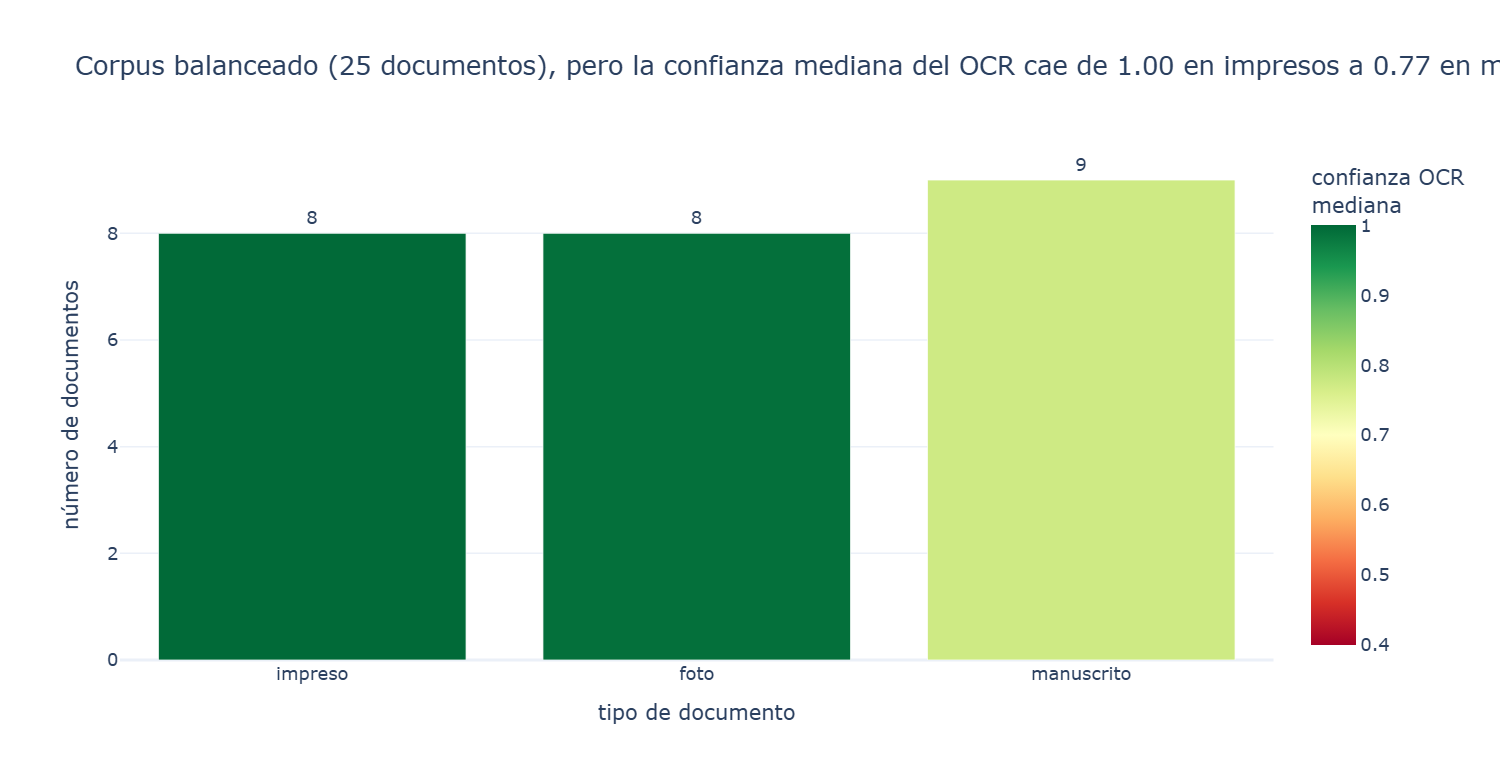

In [13]:
orden_tipos = ["impreso", "foto", "manuscrito"]
por_tipo = corpus_docs.groupby("tipo").agg(documentos=("id", "count"), conf=("confianza_mediana", "median"),
                                            dudosas=("pct_lineas_dudosas", "median")).reindex(orden_tipos).reset_index()
c_imp, c_man = por_tipo.set_index("tipo").loc["impreso", "conf"], por_tipo.set_index("tipo").loc["manuscrito", "conf"]
fig = px.bar(por_tipo, x="tipo", y="documentos", color="conf", text="documentos",
             color_continuous_scale="RdYlGn", range_color=(0.4, 1.0),
             labels={"tipo": "tipo de documento", "documentos": "número de documentos", "conf": "confianza OCR<br>mediana"},
             title=f"Corpus balanceado ({len(corpus_docs)} documentos), pero la confianza mediana del OCR "
                   f"{'cae' if c_man < c_imp else 'sube'} de {c_imp:.2f} en impresos a {c_man:.2f} en manuscritos")
fig.update_traces(textposition="outside")
t2.mostrar(fig, "01_documentos_por_tipo")

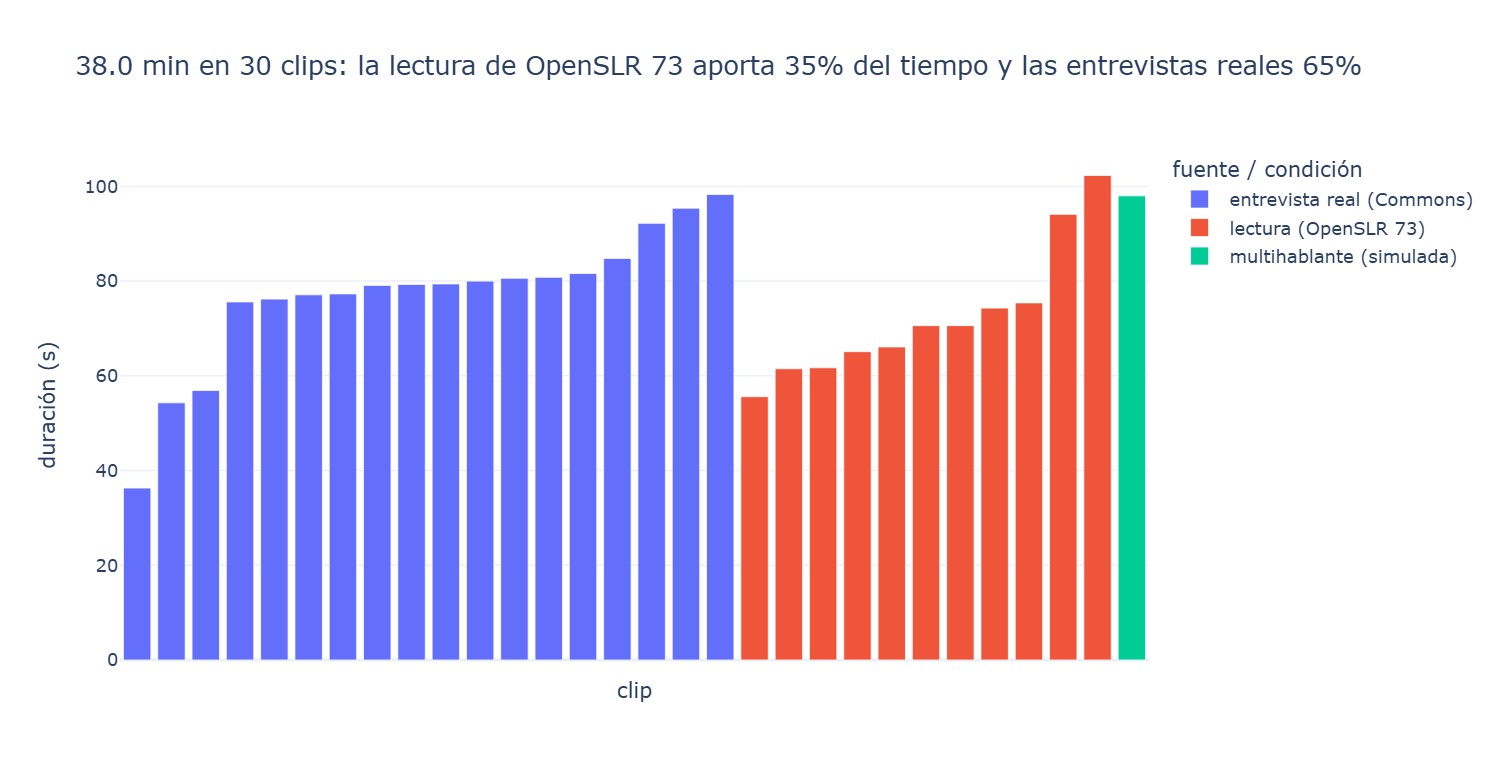

In [14]:
min_fuente = audio.groupby("condicion")["duracion_seg"].sum() / 60
pct_lect = 100 * min_fuente.get("lectura (OpenSLR 73)", 0) / min_fuente.sum()
fig = px.bar(audio.sort_values(["condicion", "duracion_seg"]), x="id", y="duracion_seg", color="condicion",
             labels={"id": "clip", "duracion_seg": "duración (s)", "condicion": "fuente / condición"},
             hover_data=["id_fuente", "n_hablantes"],
             title=f"{audio['duracion_seg'].sum() / 60:.1f} min en {len(audio)} clips: la lectura de OpenSLR 73 aporta "
                   f"{pct_lect:.0f}% del tiempo y las entrevistas reales {100 - pct_lect:.0f}%")
fig.update_xaxes(showticklabels=False)
t2.mostrar(fig, "02_duracion_por_clip")

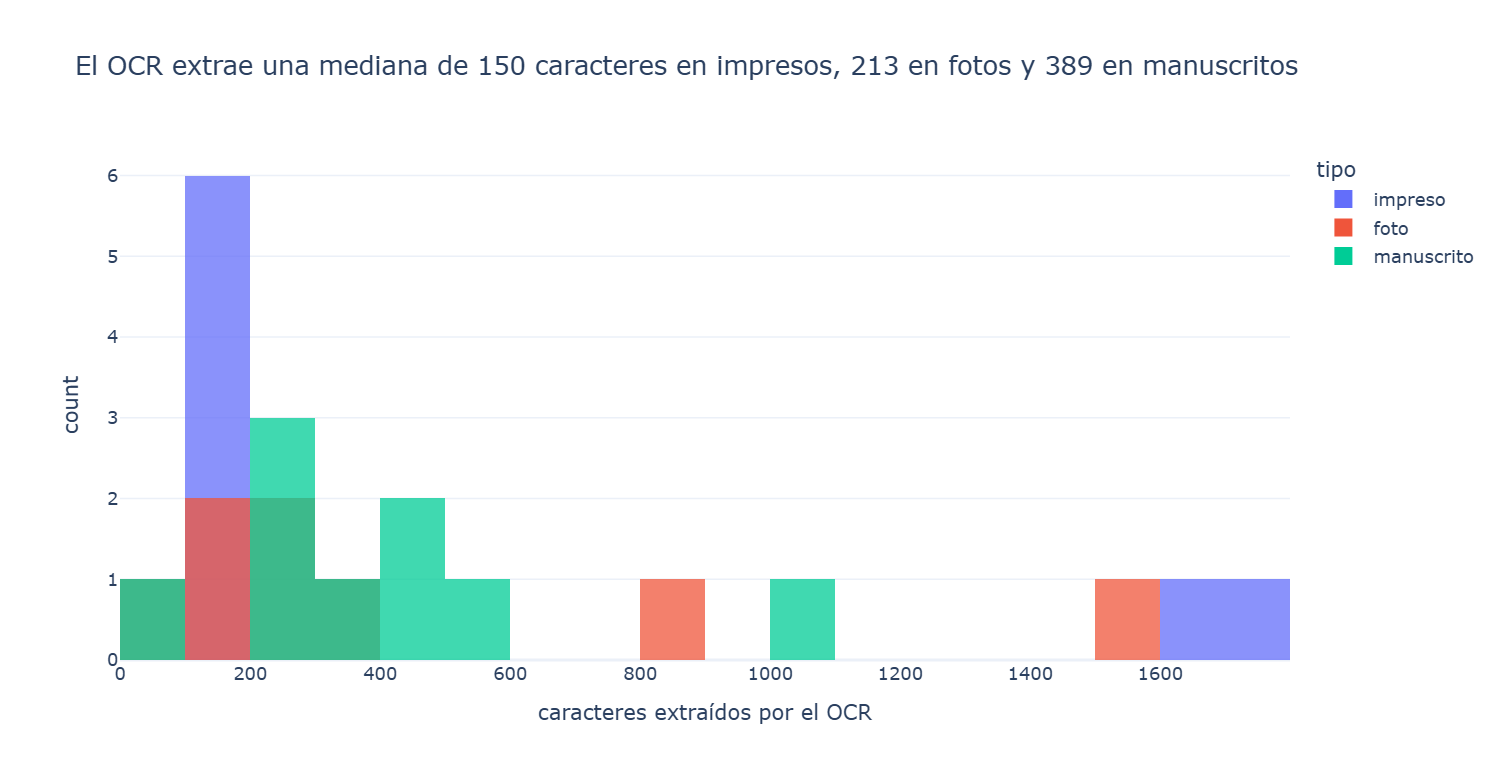

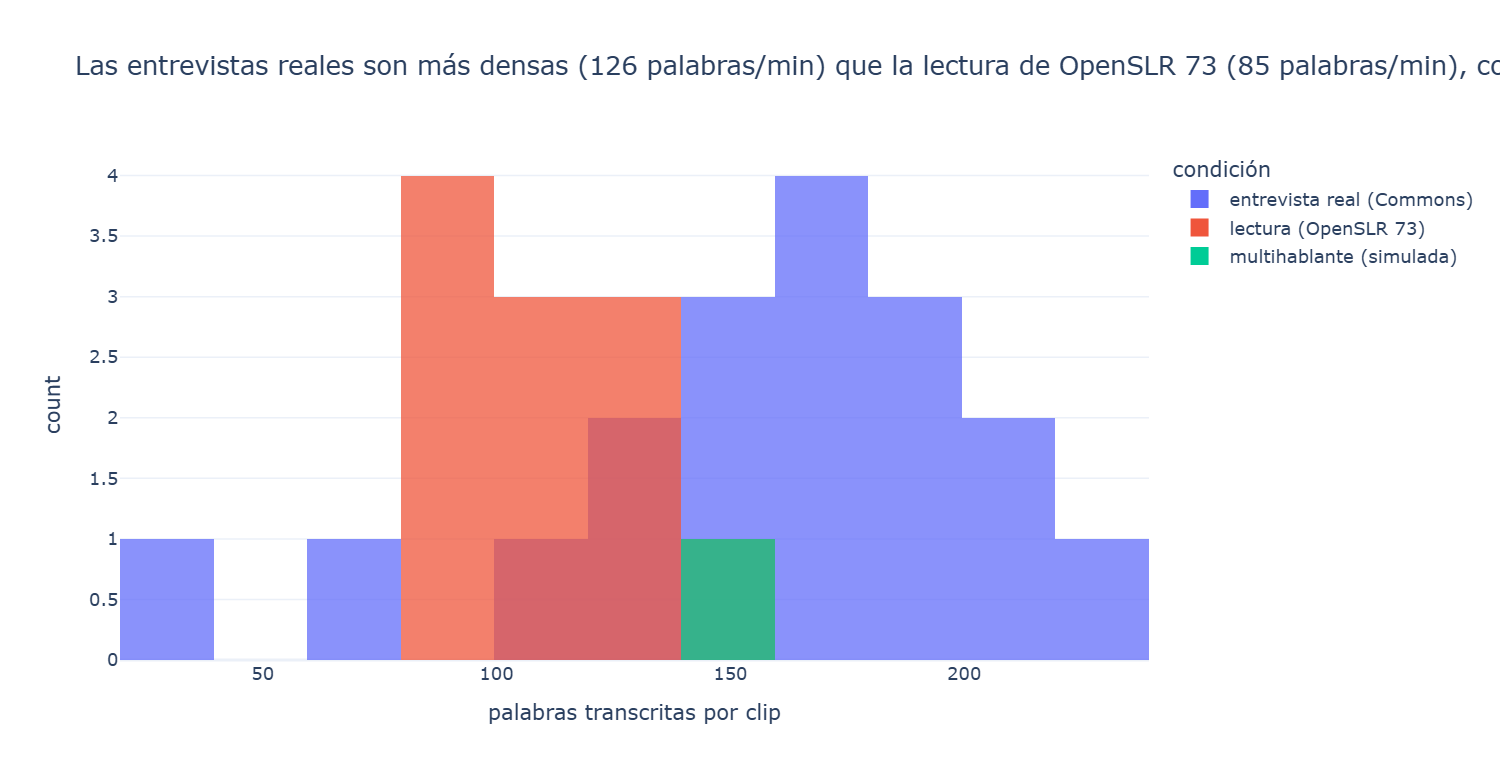

In [15]:
corpus_docs["n_caracteres_ocr"] = corpus_docs["texto_ocr"].str.len()
med = corpus_docs.groupby("tipo")["n_caracteres_ocr"].median().reindex(orden_tipos)
fig = px.histogram(corpus_docs, x="n_caracteres_ocr", color="tipo", nbins=20, barmode="overlay", opacity=0.75,
                   category_orders={"tipo": orden_tipos},
                   labels={"n_caracteres_ocr": "caracteres extraídos por el OCR", "tipo": "tipo"},
                   title=f"El OCR extrae una mediana de {med['impreso']:.0f} caracteres en impresos, "
                         f"{med['foto']:.0f} en fotos y {med['manuscrito']:.0f} en manuscritos")
t2.mostrar(fig, "03a_longitud_ocr")

audio["n_palabras_asr"] = audio["texto_asr"].map(lambda t: len(t2.normalizar(t).split()))
audio["palabras_por_min"] = audio["n_palabras_asr"] / (audio["duracion_seg"] / 60)
ppm = audio.groupby("condicion")["palabras_por_min"].median()
ppm_e, ppm_l = ppm.get("entrevista real (Commons)", float("nan")), ppm.get("lectura (OpenSLR 73)", float("nan"))
fig = px.histogram(audio, x="n_palabras_asr", color="condicion", nbins=20, barmode="overlay", opacity=0.75,
                   labels={"n_palabras_asr": "palabras transcritas por clip", "condicion": "condición"},
                   title=f"Las entrevistas reales son {'más' if ppm_e > ppm_l else 'menos'} densas ({ppm_e:.0f} palabras/min) "
                         f"que la lectura de OpenSLR 73 ({ppm_l:.0f} palabras/min), con pausas de 0,6 s entre frases")
t2.mostrar(fig, "03b_longitud_asr")

## 7 · Validación: extremos del corpus

Los tres documentos con OCR más largo y más corto, y los tres clips más largos y más cortos. Sus
valores deben coincidir con los bordes de los histogramas de arriba.

In [16]:
cols_d = ["id", "tipo", "titulo", "n_caracteres_ocr", "confianza_mediana"]
print("Documentos con OCR MÁS LARGO")
display(corpus_docs.nlargest(3, "n_caracteres_ocr")[cols_d])
print("Documentos con OCR MÁS CORTO")
display(corpus_docs.nsmallest(3, "n_caracteres_ocr")[cols_d])
for r in corpus_docs.nsmallest(3, "n_caracteres_ocr").itertuples():
    print(f"  {r.id}: {r.texto_ocr[:150]!r}")

cols_a = ["id", "condicion", "duracion_seg", "n_palabras_asr", "n_hablantes"]
print("\nClips MÁS LARGOS")
display(audio.nlargest(3, "duracion_seg")[cols_a])
print("Clips MÁS CORTOS")
display(audio.nsmallest(3, "duracion_seg")[cols_a])

assert corpus_docs["n_caracteres_ocr"].max() == corpus_docs.nlargest(1, "n_caracteres_ocr")["n_caracteres_ocr"].iloc[0]
print(f"\nRango OCR: {corpus_docs['n_caracteres_ocr'].min()}–{corpus_docs['n_caracteres_ocr'].max()} caracteres · "
      f"rango ASR: {audio['n_palabras_asr'].min()}–{audio['n_palabras_asr'].max()} palabras: coinciden con los histogramas.")
alu = audio[audio["alucinaciones"] != ""]
print(f"Clips con posibles alucinaciones de Whisper: {len(alu)}")
if len(alu):
    display(alu[["id", "condicion", "alucinaciones"]])

Documentos con OCR MÁS LARGO


,id,tipo,titulo,n_caracteres_ocr,confianza_mediana
0,doc_001,impreso,Acta de Creación de los Símbolos para el Distrito de Mache.jpg,1733,0.993
1,doc_002,impreso,Pisco-punch-mercurio-peruano-1791.jpg,1669,0.970
17,doc_021,foto,"Embassy of Hungary, Lima 3.jpg",1535,0.994


Documentos con OCR MÁS CORTO


,id,tipo,titulo,n_caracteres_ocr,confianza_mediana
20,doc_025,manuscrito,Cofradía de Nuestra Señora de la Soledad en la Villa de Pisco.jpg,30,0.6845
8,doc_010,foto,Placa Calle Capon.jpg,45,1.0000
4,doc_005,impreso,1000 Intis 1988(Front).jpg,124,0.9975


  doc_025: 'Kelle dePirco\nN I dela Soleded'
  doc_010: 'Baby Boy\nBARRIO\nCHINO\nGAS HELIO\nCALLE\nCAPON\n立'
  doc_005: 'BANCO CENTRAL DERESERVADELPERU\nB6075029N\nMILINTS\nWhifja\nS0\n28 DE JUNIO DE 1988\nDIRECTOR\nPRESIDENTE\nGERENTE GENERAL\nB6075029N'

Clips MÁS LARGOS


,id,condicion,duracion_seg,n_palabras_asr,n_hablantes
23,clip_024,lectura (OpenSLR 73),102.3,142,1
9,clip_010,entrevista real (Commons),98.3,32,2
29,clip_030,multihablante (simulada),98.0,154,2


Clips MÁS CORTOS


,id,condicion,duracion_seg,n_palabras_asr,n_hablantes
4,clip_005,entrevista real (Commons),36.3,68,2
11,clip_012,entrevista real (Commons),54.3,160,11
21,clip_022,lectura (OpenSLR 73),55.6,127,1



Rango OCR: 30–1733 caracteres · rango ASR: 32–233 palabras: coinciden con los histogramas.
Clips con posibles alucinaciones de Whisper: 0


## 8 · Descartes, exportación y ejemplos publicables

- `datos/documentos.csv` y `datos/transcripciones.csv` con las columnas obligatorias (y algunas
  auxiliares para el dashboard). `texto_referencia` se completa en la Parte 2; si ya existe, **se conserva**.
- `datos/fuentes.csv`: id, modalidad, fuente_url, licencia, autor y cómo recuperar cada archivo.
- `datos/ejemplos/`: miniaturas de los documentos con licencia libre y clips de OpenSLR 73
  (CC BY-SA 4.0, lectores voluntarios que aceptaron la publicación). Las entrevistas de Commons
  **no** se copian: el dashboard muestra su texto seudonimizado y enlaza a la página de Commons.

In [17]:
tabla_desc = pd.DataFrame(descartes, columns=["id", "modalidad", "motivo"]).drop_duplicates()
print(f"Descartes: {len(tabla_desc)}")
display(tabla_desc if len(tabla_desc) else "Sin descartes")
tabla_desc.to_csv(RAIZ / "datos" / "descartes.csv", index=False, encoding="utf-8")

Descartes: 5


,id,modalidad,motivo
0,doc_028,documento,revisión manual: no es peruano ni manuscrito (articulo botanico de Brasil)
1,doc_029,documento,revisión manual: no es manuscrito: portada impresa del Vocabulario de Gonzalez Holguin...
2,doc_023,documento,revisión manual: casi duplicado: misma placa que doc_020 (Casa Federico Elguera) fotog...
3,doc_011,documento,ilegible: el OCR devolvió 0 caracteres
4,doc_018,documento,ilegible: el OCR devolvió 5 caracteres


In [18]:
def conservar_referencias(nuevo, ruta):
    if ruta.exists():
        viejo = pd.read_csv(ruta, dtype=str, keep_default_na=False)
        if "texto_referencia" in viejo:
            ref = viejo.set_index("id")["texto_referencia"]
            nuevo["texto_referencia"] = nuevo["id"].map(ref).fillna("")
    return nuevo

EJ = RAIZ / "datos" / "ejemplos"
(EJ / "img").mkdir(parents=True, exist_ok=True)
(EJ / "audio").mkdir(parents=True, exist_ok=True)

# ── documentos.csv
d = corpus_docs.copy()
d["fuente"] = d["origen"] + " · " + d["licencia"]
d["modelo_ocr"] = MODELO_OCR
d["texto_referencia"] = ""
d = conservar_referencias(d, RAIZ / "datos" / "documentos.csv")
pub = d["origen"].str.startswith("Wikimedia") | (d.get("publicable", pd.Series("", index=d.index)).fillna("").str.lower() == "si")
d["imagen_ejemplo"] = ""
for i in d.index[pub]:
    destino = EJ / "img" / f"{d.at[i, 'id']}.jpg"
    t2.miniatura(RAIZ / d.at[i, "archivo"], destino)
    d.at[i, "imagen_ejemplo"] = destino.relative_to(RAIZ).as_posix()
cols_doc = ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia",
            "titulo", "descripcion", "licencia", "autor", "fuente_url", "n_lineas", "n_caracteres_ocr",
            "confianza_mediana", "pct_lineas_dudosas", "segundos_ocr", "imagen_ejemplo"]
documentos_csv = d[cols_doc]
documentos_csv.to_csv(RAIZ / "datos" / "documentos.csv", index=False, encoding="utf-8")

# ── transcripciones.csv
a = audio.merge(inv_a[["id_fuente", "titulo", "licencia", "autor", "fuente_url"]], on="id_fuente", how="left")
# los títulos de Commons pueden traer el nombre de la persona entrevistada: también se seudonimizan
# (la URL se conserva porque la licencia CC BY-SA exige atribuir la fuente)
a["titulo"] = a["titulo"].map(lambda t: t2.seudonimizar_texto(t, dicc, modo="documento")[0])
# y la URL pública se reemplaza por la URL estable por número de página (?curid=), que no contiene el título
urls = {f: descargar.url_curid(t) for f, t in zip(inv_a["id_fuente"], inv_a["titulo"]) if str(t) and inv_a.set_index("id_fuente").at[f, "origen"].startswith("Wikimedia")}
a["fuente_url"] = [urls.get(f, u) for f, u in zip(a["id_fuente"], a["fuente_url"])]
a["idioma"] = "es (variante peruana documentada por la fuente)"
a["modelo_asr"] = MODELO_ASR
a["texto_referencia"] = ""
a = conservar_referencias(a, RAIZ / "datos" / "transcripciones.csv")
a["audio_ejemplo"] = ""
for i in a.index[a["origen"] == "OpenSLR 73"]:
    # WAV de 16 bits: el codificador OGG/Vorbis de libsndfile se cae en Windows (stack overflow)
    destino = EJ / "audio" / f"{a.at[i, 'id']}.wav"
    if not destino.exists():
        x, _ = sf.read(RAIZ / a.at[i, "archivo_audio"], dtype="int16")
        sf.write(destino, x, SR, subtype="PCM_16")
    a.at[i, "audio_ejemplo"] = destino.relative_to(RAIZ).as_posix()
cols_aud = ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia",
            "id_fuente", "condicion", "origen", "titulo", "licencia", "autor", "fuente_url", "inicio_seg", "fin_seg",
            "segundos_voz", "diarizado", "n_palabras_asr", "segundos_asr", "rtf", "alucinaciones", "audio_ejemplo"]
transcripciones_csv = a[cols_aud]
transcripciones_csv.to_csv(RAIZ / "datos" / "transcripciones.csv", index=False, encoding="utf-8")

# ── fuentes.csv
def acceso_audio(r):
    if r.origen == "OpenSLR 73":
        meta = RAIZ / Path(inv_a.set_index("id_fuente").at[r.id_fuente, "archivo"]).with_suffix(".json")
        frases = json.loads(meta.read_text(encoding="utf-8"))["frases"] if meta.exists() else []
        return f"OpenSLR 73 (es_pe_female/male.zip): frases {', '.join(frases)}; reconstruir con src/descargar.py" if frases else \
               "OpenSLR 73: montaje de la entrevista simulada en src/descargar.py (openslr73)"
    return f"Commons: '{r.titulo}', tramo {r.inicio_seg:.0f}-{r.fin_seg:.0f} s; descargar con src/descargar.py"

f_doc = pd.DataFrame({"id": d["id"], "modalidad": "documento", "fuente_url": d["fuente_url"], "licencia": d["licencia"],
                      "autor": d["autor"], "titulo": d["titulo"],
                      "acceso": d.apply(lambda r: f"Commons API: File:{r.titulo} (src/descargar.py)" if r.fuente_url else
                                        "Captura propia del estudiante (datos/propios/)", axis=1),
                      "fecha_extraccion": time.strftime("%Y-%m-%d")})
f_aud = pd.DataFrame({"id": a["id"], "modalidad": "audio", "fuente_url": a["fuente_url"], "licencia": a["licencia"],
                      "autor": a["autor"], "titulo": a["titulo"], "acceso": [acceso_audio(r) for r in a.itertuples()],
                      "fecha_extraccion": time.strftime("%Y-%m-%d")})
fuentes_csv = pd.concat([f_doc, f_aud], ignore_index=True)
fuentes_csv.to_csv(RAIZ / "datos" / "fuentes.csv", index=False, encoding="utf-8")

for nombre, df in [("documentos.csv", documentos_csv), ("transcripciones.csv", transcripciones_csv), ("fuentes.csv", fuentes_csv)]:
    print(f"datos/{nombre}: shape = {df.shape}")

datos/documentos.csv: shape = (25, 18)
datos/transcripciones.csv: shape = (30, 24)
datos/fuentes.csv: shape = (55, 8)


In [19]:
documentos_csv[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]].head(5)

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (verificado en Sesión 10) · CC BY 4.0,SERESUELVE:\n.- Artículo 1°- RECONOCER como lema ganador en el Concurso Público\nCreac...,PaddleOCR 3.7.0 PP-OCRv6 · motor transformers (PyTorch) · cpu · sin preprocesamiento e...,
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (verificado en Sesión 10) · Public domain,Eol. 25.\nMERCURIO PERUANO\nDEL DIA 13. DE ENERO DE 1791.\nの\nEXAMEN HISTÓRICO DE LAS ...,PaddleOCR 3.7.0 PP-OCRv6 · motor transformers (PyTorch) · cpu · sin preprocesamiento e...,
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (verificado en Sesión 10) · CC0,A3967812Q\nBANCOCENTRAL\nDERESERVADELPERU\nI\nDIEZ INTIS\n26 DE JUNIO DE 1987\nifeuei\...,PaddleOCR 3.7.0 PP-OCRv6 · motor transformers (PyTorch) · cpu · sin preprocesamiento e...,BANCO CENTRAL DE RESERVA DEL PERU\nDIEZ INTIS\n26 DE JUNIO DE 1987 \nA3967812Q
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (verificado en Sesión 10) · CC0,BANCO CENTRALDERESERVAdI PERÚ\n100\nB4496556D\n100\n26 DE JUNIO DE 1987\n0\n1-A2\n feu...,PaddleOCR 3.7.0 PP-OCRv6 · motor transformers (PyTorch) · cpu · sin preprocesamiento e...,
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (verificado en Sesión 10) · CC0,BANCO CENTRAL DERESERVADELPERU\nB6075029N\nMILINTS\nWhifja\nS0\n28 DE JUNIO DE 1988\nD...,PaddleOCR 3.7.0 PP-OCRv6 · motor transformers (PyTorch) · cpu · sin preprocesamiento e...,BANCO CENTRAL DE RESERVA DEL PERU\nMIL INTIS\n28 DE JUNIO DE 1988 \nB6075029N


In [20]:
transcripciones_csv[["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia"]].head(5)

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clips/clip_001.wav,79.4,es (variante peruana documentada por la fuente),"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme s...","faster-whisper small (Systran/faster-whisper-small, int8, CPU) · beam 5 · VAD Silero o...",2,
1,clip_002,datos/raw/audio/clips/clip_002.wav,56.9,es (variante peruana documentada por la fuente),"[HABLANTE_1] Nuestros jugadores ¿no? [HABLANTE_2] Muy bien, o sea, está diciendo que e...","faster-whisper small (Systran/faster-whisper-small, int8, CPU) · beam 5 · VAD Silero o...",2,
2,clip_003,datos/raw/audio/clips/clip_003.wav,75.6,es (variante peruana documentada por la fuente),[HABLANTE_1] Buenos días profesor y compañeros hoy estoy cerca de aquí por mi casa y v...,"faster-whisper small (Systran/faster-whisper-small, int8, CPU) · beam 5 · VAD Silero o...",1,
3,clip_004,datos/raw/audio/clips/clip_004.wav,77.1,es (variante peruana documentada por la fuente),[HABLANTE_1] para jugar y ha metido unos cuantos goles. Ha metido goles. [HABLANTE_2] ...,"faster-whisper small (Systran/faster-whisper-small, int8, CPU) · beam 5 · VAD Silero o...",3,
4,clip_005,datos/raw/audio/clips/clip_005.wav,36.3,es (variante peruana documentada por la fuente),[HABLANTE_1] los peruanos tanto como fuera de el país también y es este un deporte que...,"faster-whisper small (Systran/faster-whisper-small, int8, CPU) · beam 5 · VAD Silero o...",2,


In [21]:
fuentes_csv.head(5)

,id,modalidad,fuente_url,licencia,autor,titulo,acceso,fecha_extraccion
0,doc_001,documento,https://commons.wikimedia.org/wiki/File:Acta_de_Creaci%C3%B3n_de_los_S%C3%ADmbolos_par...,CC BY 4.0,Helder Zavaleta Verde,Acta de Creación de los Símbolos para el Distrito de Mache.jpg,Commons API: File:Acta de Creación de los Símbolos para el Distrito de Mache.jpg (src/...,2026-10-25
1,doc_002,documento,https://commons.wikimedia.org/wiki/File:Pisco-punch-mercurio-peruano-1791.jpg,Public domain,El Mercurio Peruano,Pisco-punch-mercurio-peruano-1791.jpg,Commons API: File:Pisco-punch-mercurio-peruano-1791.jpg (src/descargar.py),2026-10-25
2,doc_003,documento,https://commons.wikimedia.org/wiki/File:10_Intis_1987(front).jpg,CC0,ByRussia45,10 Intis 1987(front).jpg,Commons API: File:10 Intis 1987(front).jpg (src/descargar.py),2026-10-25
3,doc_004,documento,https://commons.wikimedia.org/wiki/File:100_Intis_1987(Front).jpg,CC0,ByRussia45,100 Intis 1987(Front).jpg,Commons API: File:100 Intis 1987(Front).jpg (src/descargar.py),2026-10-25
4,doc_005,documento,https://commons.wikimedia.org/wiki/File:1000_Intis_1988(Front).jpg,CC0,ByRussia45,1000 Intis 1988(Front).jpg,Commons API: File:1000 Intis 1988(Front).jpg (src/descargar.py),2026-10-25


## 9 · Verificación de los mínimos de la tarea

In [22]:
minutos = transcripciones_csv["duracion_seg"].sum() / 60
chequeos = {
    "≥ 25 documentos": len(documentos_csv) >= 25,
    "8 impresos, 8 fotos, 9 manuscritos": documentos_csv["tipo"].value_counts().reindex(orden_tipos).tolist() == [8, 8, 9],
    "≥ 30 min de audio": minutos >= 30,
    "≥ 20 clips": len(transcripciones_csv) >= 20,
    "≥ 1 clip multihablante (diarizado con 2+ hablantes)": (transcripciones_csv["n_hablantes"] >= 2).any(),
    "licencia registrada en cada archivo": fuentes_csv["licencia"].astype(str).str.len().gt(0).all(),
    "sin archivos > 100 MB en datos/ fuera de raw/": all(p.stat().st_size < 100e6 for p in (RAIZ / "datos").rglob("*")
                                                          if p.is_file() and "raw" not in p.parts),
}
for k, v in chequeos.items():
    print(("✅" if v else "❌"), k)
print(f"\nTotal: {len(documentos_csv)} documentos · {minutos:.1f} min en {len(transcripciones_csv)} clips · "
      f"{(transcripciones_csv['n_hablantes'] >= 2).sum()} clips con 2+ hablantes")

✅ ≥ 25 documentos
✅ 8 impresos, 8 fotos, 9 manuscritos
✅ ≥ 30 min de audio
✅ ≥ 20 clips
✅ ≥ 1 clip multihablante (diarizado con 2+ hablantes)
✅ licencia registrada en cada archivo
✅ sin archivos > 100 MB en datos/ fuera de raw/

Total: 25 documentos · 38.0 min en 30 clips · 15 clips con 2+ hablantes
